In [74]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from keras.layers import Dense
from keras.models import Sequential

In [75]:
X,y = make_moons(n_samples=250,noise=0.2,random_state=42)

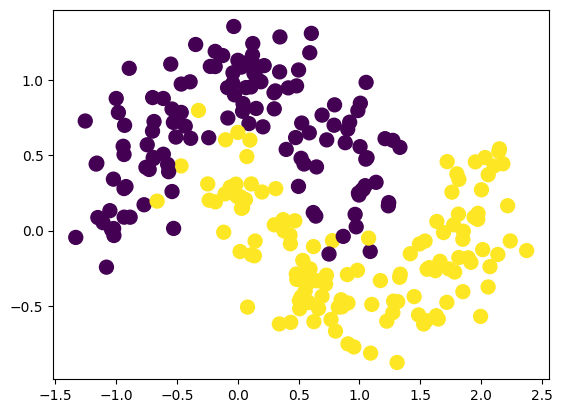

In [76]:
plt.scatter(X[:,0],X[:,1],c=y,s=100)
plt.show()

In [77]:
model = Sequential()

model.add(Dense(10,activation='sigmoid',input_dim=2))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(1,activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [78]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [79]:
old_weights = model.get_weights()[0]

In [80]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [81]:
model.fit(X_train,y_train,epochs=100,batch_size=10)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.4900 - loss: 0.7203
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4900 - loss: 0.7095
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4900 - loss: 0.7016
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4900 - loss: 0.6979
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4900 - loss: 0.6954
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4900 - loss: 0.6943
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4900 - loss: 0.6938 
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4900 - loss: 0.6937
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5000 - loss: 0.6932
Epoch 10/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5100 - loss: 0.6934
Epoch 11/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5100 - loss: 0.6932
Epoch 12/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy

In [82]:
new_weights = model.get_weights()[0]

In [83]:
model.optimizer.get_config()['learning_rate']

0.0010000000474974513

In [84]:
gradient = (old_weights - new_weights)/0.001
percent_change = abs(100*(old_weights-new_weights)/old_weights)
gradient

array([[  409.47662 ,   123.23832 ,  -254.74127 ,  -469.61603 ,
          -74.2945  ,    67.0551  ,    33.240376,   454.2576  ,
          109.60239 ,  -304.6932  ],
       [-1794.9365  , -1777.8673  ,  1524.2888  ,  1810.7727  ,
         1562.176   ,  1414.8539  ,  1445.1558  , -1899.7164  ,
        -1723.4844  ,  1823.4912  ]], dtype=float32)

In [85]:
percent_change

array([[2.7197452e+02, 1.8783144e+01, 5.2361169e+02, 1.7098236e+03,
        1.3090437e+01, 1.6833822e+01, 5.6127262e+00, 3.6976266e+02,
        1.7715015e+01, 8.5005737e+01],
       [9.2350250e+02, 3.7573087e+02, 1.7354460e+03, 2.9649615e+02,
        4.4070505e+02, 2.7204626e+02, 1.9555485e+03, 1.2718258e+05,
        4.2141922e+02, 3.9495875e+04]], dtype=float32)

In [86]:
loss_function = tf.keras.losses.BinaryCrossentropy()

with tf.GradientTape() as tape:

    predictions = model(X_train[:32], training=True)

    loss = loss_function(
        tf.cast(y_train[:32], tf.float32),
        predictions
    )

gradients = tape.gradient(
    loss,
    model.trainable_variables
)

for i, layer in enumerate(model.layers):

    kernel_gradient = gradients[2*i]

    gradient_norm = tf.norm(kernel_gradient)

    print(layer.name, gradient_norm.numpy())

dense_60 0.09126939
dense_61 0.17823173
dense_62 0.09591893
dense_63 0.05454187
dense_64 0.027437871
dense_65 0.015541029
dense_66 0.009548202
dense_67 0.008523131
dense_68 0.013720063
dense_69 0.053471997


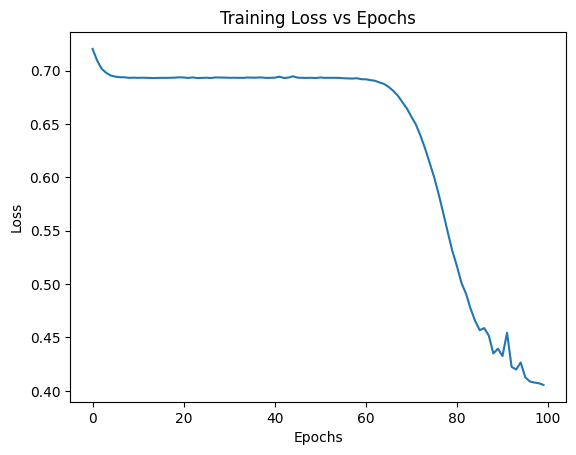

In [87]:
plt.plot(model.history.history['loss'])
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss vs Epochs')
plt.show()

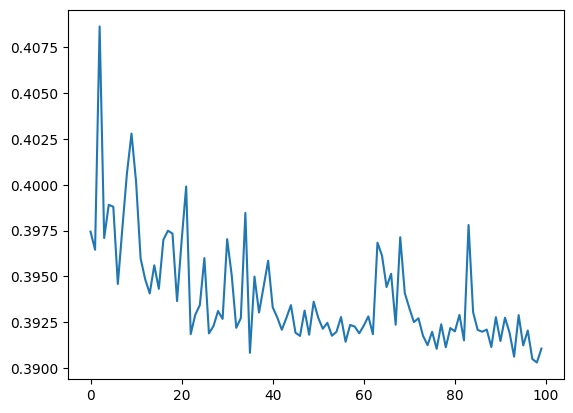

In [88]:
plt.plot(history.history['loss'])
plt.show()

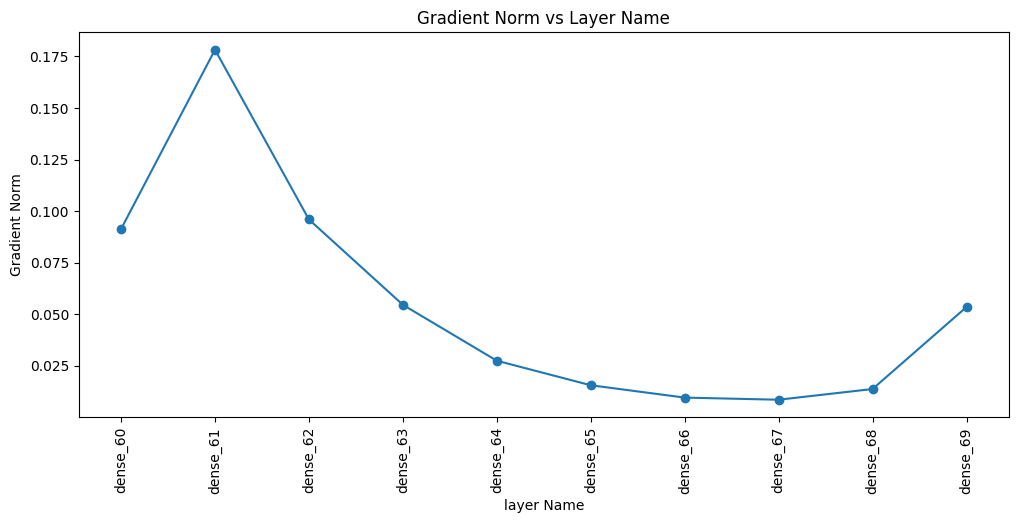

In [94]:
layers_names = []
gradient_values = []

for i,layer in enumerate(model.layers):
  kernel_gradient = gradients[2*i]
  gradient_norm = tf.norm(kernel_gradient)

  layers_names.append(layer.name)
  gradient_values.append(gradient_norm.numpy())
plt.figure(figsize=(12,5))
plt.plot(layers_names,gradient_values,marker='o')
plt.xlabel('layer Name')
plt.ylabel('Gradient Norm')
plt.title('Gradient Norm vs Layer Name')
plt.xticks(rotation=90)
plt.show()